In [7]:
# ============================================================
# Pipeline complet avec affichages intermédiaires
# ============================================================
import tarfile
import pandas as pd
import os
import numpy as np
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
from sklearn.preprocessing import label_binarize

print("="*60)
print("ÉTAPE 0 : Montage et extraction")
print("="*60)
drive.mount('/content/drive')
tar_path = '/content/drive/MyDrive/TCGA-PANCAN-HiSeq-801x20531.tar.gz'
extract_path = '/content/data'
with tarfile.open(tar_path, 'r:gz') as tar:
    tar.extractall(path=extract_path)
print("Extraction terminée.\n")

print("="*60)
print("ÉTAPE 1 : Chargement des données")
print("="*60)
data_csv = os.path.join(extract_path, 'TCGA-PANCAN-HiSeq-801x20531', 'data.csv')
labels_csv = os.path.join(extract_path, 'TCGA-PANCAN-HiSeq-801x20531', 'labels.csv')
X = pd.read_csv(data_csv, index_col=0)
y_df = pd.read_csv(labels_csv, index_col=0)
y = y_df['Class'] if 'Class' in y_df.columns else y_df.iloc[:, 0]
print(f"X shape : {X.shape}")
print(f"y shape : {y.shape}")
print(f"Types de cancer : {y.unique()}")
print(y.value_counts())
print("\nExtrait X (5x5) :")
print(X.iloc[:5, :5])
print(f"Valeur min : {X.min().min():.2f}, max : {X.max().max():.2f}\n")

print("="*60)
print("ÉTAPE 2 : Imputation (si nécessaire)")
print("="*60)
if X.isnull().sum().sum() > 0:
    from sklearn.impute import KNNImputer
    X = pd.DataFrame(KNNImputer().fit_transform(X), index=X.index, columns=X.columns)
    print("Imputation effectuée.")
else:
    print("Aucun NaN détecté.\n")

print("="*60)
print("ÉTAPE 3 : Encodage et split (75% train, 25% test)")
print("="*60)
le = LabelEncoder()
y_enc = le.fit_transform(y)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.25, random_state=42, stratify=y_enc
)
print(f"X_train shape : {X_train.shape}")
print(f"X_test shape  : {X_test.shape}")
print(f"y_train distribution : {dict(zip(*np.unique(y_train, return_counts=True)))}")
print(f"y_test distribution  : {dict(zip(*np.unique(y_test, return_counts=True)))}")
print("\nExtrait X_train (5x5) :")
print(X_train.iloc[:5, :5])
print()

print("="*60)
print("ÉTAPE 4 : VarianceThreshold (seuil=0.04)")
print("="*60)
var_selector = VarianceThreshold(threshold=0.04)
X_train_var = var_selector.fit_transform(X_train)
X_test_var = var_selector.transform(X_test)
cols_kept = X.columns[var_selector.get_support()]
X_train_var = pd.DataFrame(X_train_var, columns=cols_kept)
X_test_var = pd.DataFrame(X_test_var, columns=cols_kept)
print(f"Ancien nombre de gènes : {X_train.shape[1]}")
print(f"Nouveau nombre de gènes : {X_train_var.shape[1]}")
print(f"Gènes supprimés : {X_train.shape[1] - X_train_var.shape[1]}")
print("\nExtrait X_train_var (5x5) :")
print(X_train_var.iloc[:5, :5])
print()

print("="*60)
print("ÉTAPE 5 : SelectKBest (k=100) – supervisé")
print("="*60)
selector = SelectKBest(f_classif, k=100)
X_train_100 = selector.fit_transform(X_train_var, y_train)
X_test_100 = selector.transform(X_test_var)
selected_genes_100 = cols_kept[selector.get_support()]
print(f"Nombre de gènes sélectionnés : {X_train_100.shape[1]}")
print("Indices des 5 premiers gènes sélectionnés :", selected_genes_100[:5].tolist())
print("\nExtrait X_train_100 (5x5) :")
print(pd.DataFrame(X_train_100[:5, :5]))
print()

print("="*60)
print("ÉTAPE 6 : Random Forest pour l'importance (sur 100 gènes)")
print("="*60)
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train_100, y_train)
importances = pd.Series(rf.feature_importances_, index=selected_genes_100)
top10_genes = importances.nlargest(10).index
print("Top 10 biomarqueurs (importance) :")
for i, gene in enumerate(top10_genes, 1):
    print(f"{i:2d}. {gene} (importance = {importances[gene]:.4f})")
print()

print("="*60)
print("ÉTAPE 7 : Réduction aux 10 biomarqueurs")
print("="*60)
indices_top10 = [list(selected_genes_100).index(g) for g in top10_genes]
X_train_top10 = X_train_100[:, indices_top10]
X_test_top10 = X_test_100[:, indices_top10]
print(f"X_train_top10 shape : {X_train_top10.shape}")
print(f"X_test_top10 shape  : {X_test_top10.shape}")
print("\nExtrait X_train_top10 (5x5) :")
print(pd.DataFrame(X_train_top10[:5, :5]))
print()

print("="*60)
print("ÉTAPE 8 : Régression logistique régularisée (C=0.001)")
print("="*60)
lr = LogisticRegression(C=0.001, max_iter=1000, random_state=42, penalty='l2')
lr.fit(X_train_top10, y_train)
y_pred = lr.predict(X_test_top10)
y_proba = lr.predict_proba(X_test_top10)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted')
y_test_bin = label_binarize(y_test, classes=range(len(le.classes_)))
auc = roc_auc_score(y_test_bin, y_proba, average='macro', multi_class='ovr')

print(f"Accuracy  : {acc:.4f}")
print(f"F1 (weighted) : {f1:.4f}")
print(f"AUC macro : {auc:.4f}\n")

print("="*60)
print("Rapport de classification")
print("="*60)
print(classification_report(y_test, y_pred, target_names=le.classes_))

ÉTAPE 0 : Montage et extraction
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_2474/3527390141.py:24: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_path)


Extraction terminée.

ÉTAPE 1 : Chargement des données
X shape : (801, 20531)
y shape : (801,)
Types de cancer : ['PRAD' 'LUAD' 'BRCA' 'KIRC' 'COAD']
Class
BRCA    300
KIRC    146
LUAD    141
PRAD    136
COAD     78
Name: count, dtype: int64

Extrait X (5x5) :
          gene_0    gene_1    gene_2    gene_3     gene_4
sample_0     0.0  2.017209  3.265527  5.478487  10.431999
sample_1     0.0  0.592732  1.588421  7.586157   9.623011
sample_2     0.0  3.511759  4.327199  6.881787   9.870730
sample_3     0.0  3.663618  4.507649  6.659068  10.196184
sample_4     0.0  2.655741  2.821547  6.539454   9.738265
Valeur min : 0.00, max : 20.78

ÉTAPE 2 : Imputation (si nécessaire)
Aucun NaN détecté.

ÉTAPE 3 : Encodage et split (75% train, 25% test)
X_train shape : (600, 20531)
X_test shape  : (201, 20531)
y_train distribution : {np.int64(0): np.int64(225), np.int64(1): np.int64(58), np.int64(2): np.int64(109), np.int64(3): np.int64(106), np.int64(4): np.int64(102)}
y_test distribution  : {np.int6

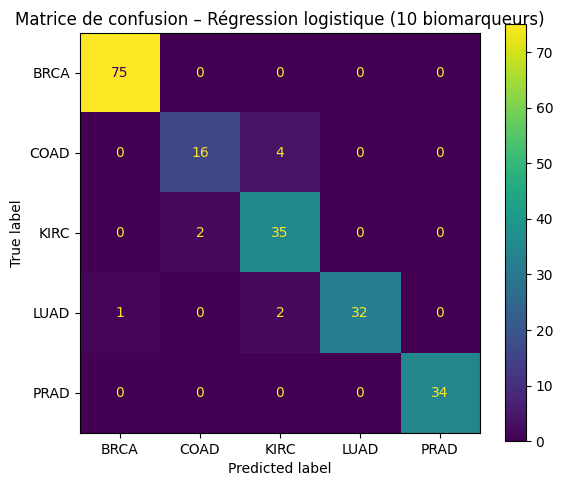

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_, ax=ax)
ax.set_title("Matrice de confusion – Régression logistique (10 biomarqueurs)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

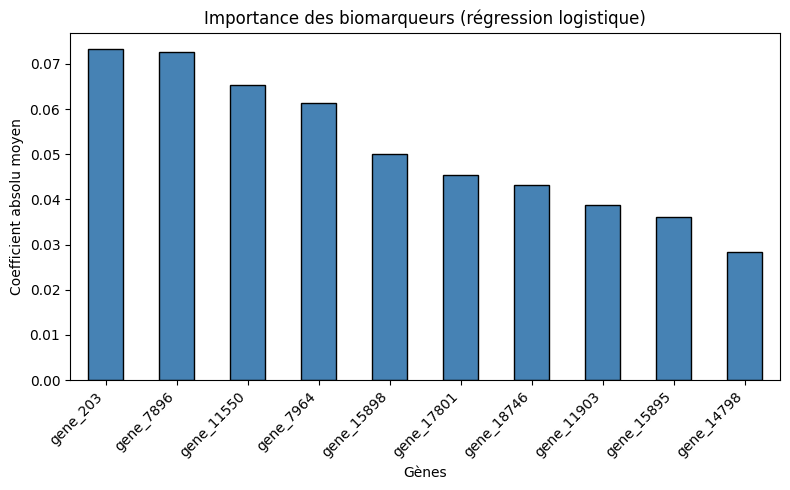


Top 5 biomarqueurs les plus influents :
gene_203      0.073226
gene_7896     0.072580
gene_11550    0.065297
gene_7964     0.061400
gene_15898    0.050052
dtype: float64


In [9]:
# ============================================================
# AJOUT 2 : Importance des biomarqueurs (coefficients moyens absolus)
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt

coef_abs_mean = np.abs(lr.coef_).mean(axis=0)
importance_series = pd.Series(coef_abs_mean, index=top10_genes).sort_values(ascending=False)

plt.figure(figsize=(8,5))
importance_series.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title("Importance des biomarqueurs (régression logistique)")
plt.ylabel("Coefficient absolu moyen")
plt.xlabel("Gènes")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("biomarker_importance.png", dpi=150)
plt.show()

print("\nTop 5 biomarqueurs les plus influents :")
print(importance_series.head(5))

Calcul du t-SNE sur l'ensemble des patients (peut prendre 1-2 min)...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


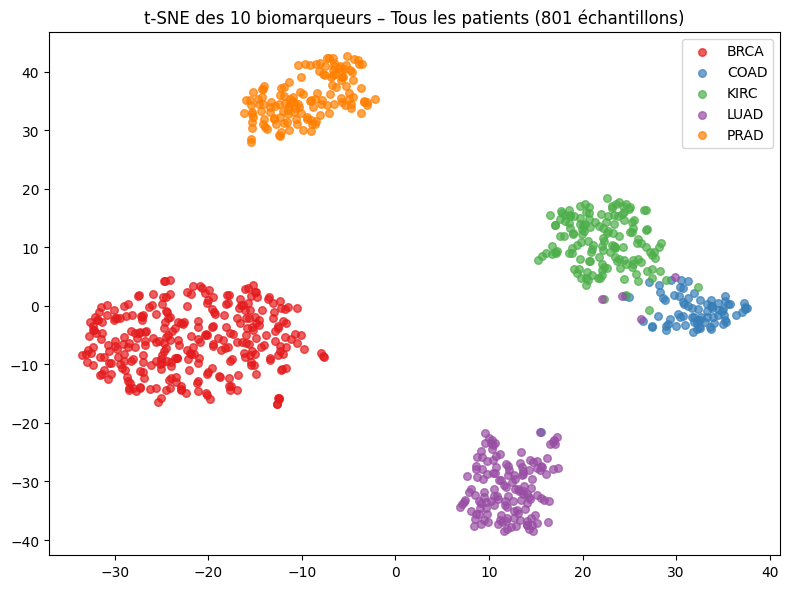

In [10]:
# ============================================================
# Visualisations PCA et t-SNE sur l'ensemble des patients (10 biomarqueurs)
# ============================================================
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Concaténer les données d'entraînement et de test sur les 10 biomarqueurs
X_all = np.vstack([X_train_top10, X_test_top10])
y_all = np.concatenate([y_train, y_test])

# Normalisation (indispensable pour PCA et t-SNE)
scaler = StandardScaler()
X_all_scaled = scaler.fit_transform(X_all)




# ---------- t-SNE ----------
print("Calcul du t-SNE sur l'ensemble des patients (peut prendre 1-2 min)...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
X_all_tsne = tsne.fit_transform(X_all_scaled)

plt.figure(figsize=(8, 6))
for i, cancer in enumerate(le.classes_):
    mask = (y_all == i)
    plt.scatter(X_all_tsne[mask, 0], X_all_tsne[mask, 1],
                label=cancer, alpha=0.7, s=30, c=colors[i])
plt.title(f"t‑SNE des 10 biomarqueurs – Tous les patients ({len(y_all)} échantillons)")
plt.legend()
plt.tight_layout()
plt.savefig("tsne_all_patients.png", dpi=150)
plt.show()

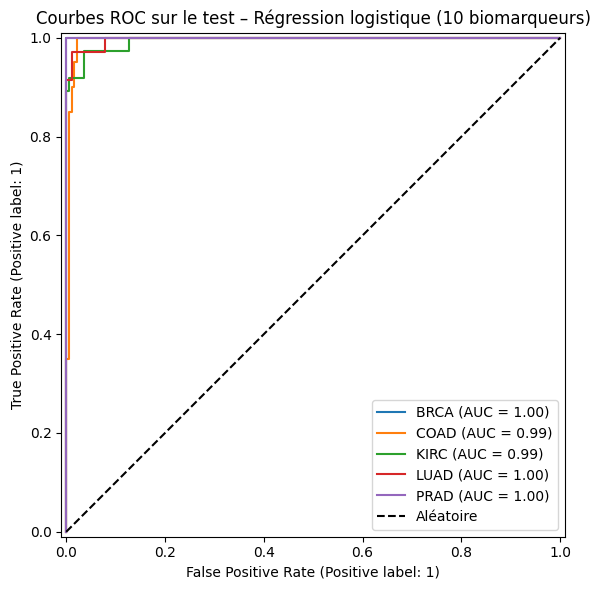

In [11]:
# ============================================================
# Courbes ROC sur le jeu de test (régression logistique)
# ============================================================
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))
for i, cancer in enumerate(le.classes_):
    RocCurveDisplay.from_predictions(
        y_test == i,          # binarisation de la classe i
        y_proba[:, i],        # probabilités pour cette classe
        name=cancer,
        ax=ax
    )
ax.plot([0, 1], [0, 1], 'k--', label="Aléatoire")
ax.set_title("Courbes ROC sur le test – Régression logistique (10 biomarqueurs)")
ax.legend()
plt.tight_layout()
plt.savefig("roc_curves_test.png", dpi=150)
plt.show()


Association des 10 biomarqueurs à un type de cancer
Gène gene_7964    → indicateur pour BRCA  (coefficient = -0.154, effet négatif)
Gène gene_18746   → indicateur pour COAD  (coefficient = -0.098, effet négatif)
Gène gene_17801   → indicateur pour BRCA  (coefficient = -0.113, effet négatif)
Gène gene_15895   → indicateur pour LUAD  (coefficient = 0.090, effet positif)
Gène gene_203     → indicateur pour PRAD  (coefficient = 0.183, effet positif)
Gène gene_14798   → indicateur pour PRAD  (coefficient = 0.071, effet positif)
Gène gene_15898   → indicateur pour LUAD  (coefficient = 0.125, effet positif)
Gène gene_11550   → indicateur pour KIRC  (coefficient = 0.091, effet positif)
Gène gene_7896    → indicateur pour COAD  (coefficient = 0.122, effet positif)
Gène gene_11903   → indicateur pour LUAD  (coefficient = 0.086, effet positif)


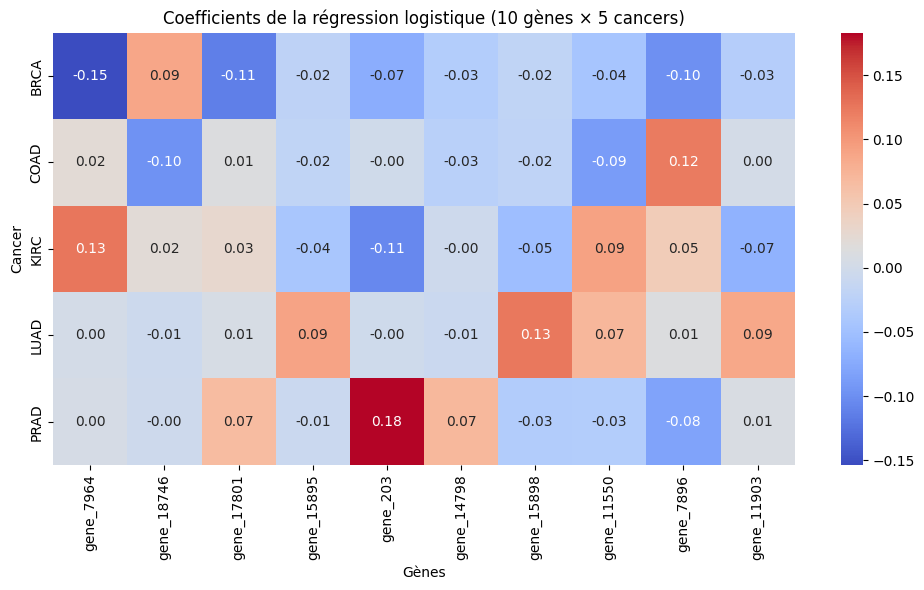

In [51]:
# ============================================================
# Association gène ↔ cancer (basée sur les coefficients de la régression logistique)
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Récupérer les coefficients : shape (n_classes, n_features)
coefs = lr.coef_  # (5, 10)
cancer_names = le.classes_

# Pour chaque gène, trouver la classe avec le coefficient absolu maximal
gene_cancer_map = []
for j, gene in enumerate(top10_genes):
    abs_coefs = np.abs(coefs[:, j])
    best_class_idx = np.argmax(abs_coefs)
    best_cancer = cancer_names[best_class_idx]
    best_coef = coefs[best_class_idx, j]
    signe = "positif" if best_coef > 0 else "négatif"
    gene_cancer_map.append((gene, best_cancer, best_coef, signe))

# Affichage
print("\n" + "="*60)
print("Association des 10 biomarqueurs à un type de cancer")
print("="*60)
for gene, cancer, coef, signe in gene_cancer_map:
    print(f"Gène {gene:12s} → indicateur pour {cancer:5s} (coefficient = {coef:.3f}, effet {signe})")

# Option : heatmap des coefficients (tous les gènes vs tous les cancers)
plt.figure(figsize=(10, 6))
sns.heatmap(coefs, annot=True, fmt='.2f', cmap='coolwarm',
            xticklabels=top10_genes, yticklabels=cancer_names)
plt.title("Coefficients de la régression logistique (10 gènes × 5 cancers)")
plt.xlabel("Gènes")
plt.ylabel("Cancer")
plt.tight_layout()
plt.savefig("coefficients_heatmap.png", dpi=150)
plt.show()

ExactExplainer explainer: 202it [00:13,  4.58it/s]


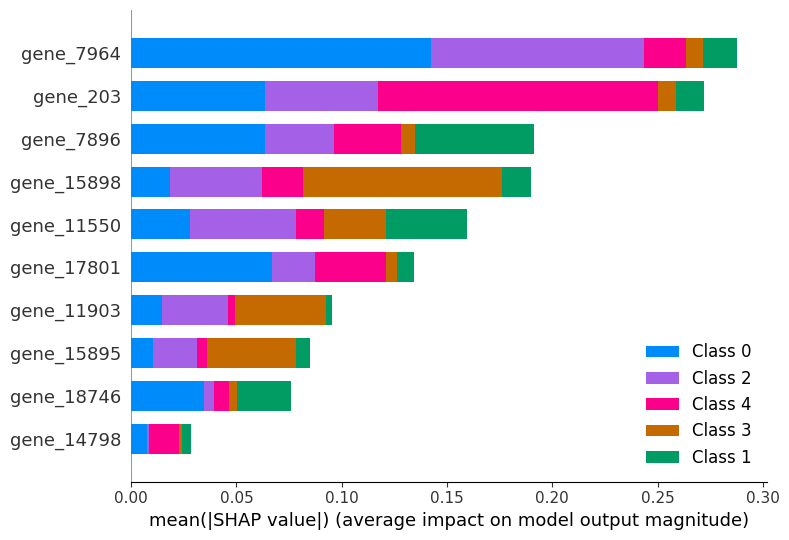

<Figure size 640x480 with 0 Axes>

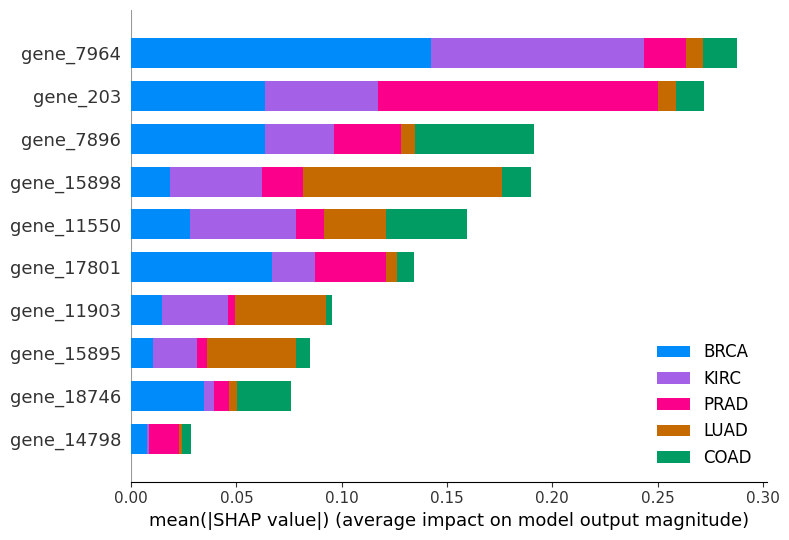

<Figure size 640x480 with 0 Axes>

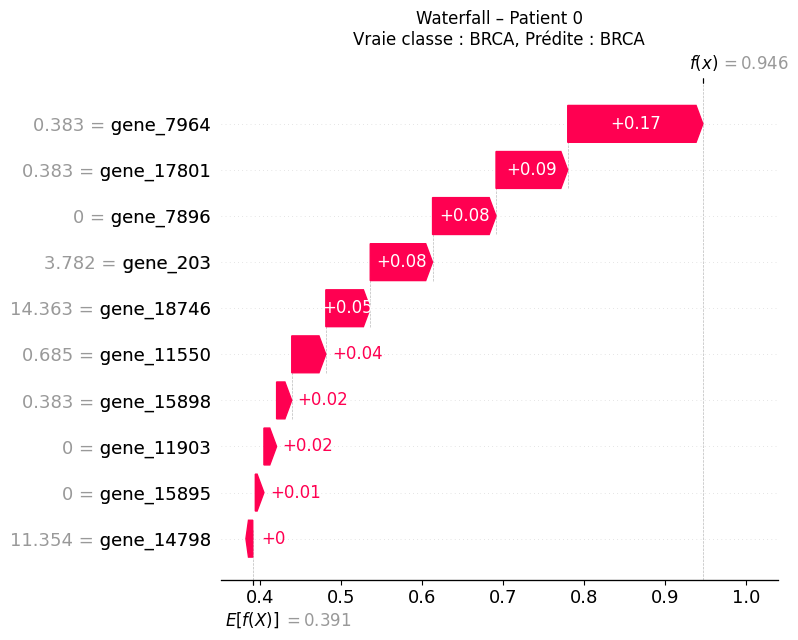

In [13]:
# ============================================================
# SHAP avec noms des cancers – figures utiles uniquement
# ============================================================
!pip install shap -q
import shap
import numpy as np
import matplotlib.pyplot as plt

# Explainer pour le modèle multi‑classe
explainer = shap.Explainer(lr.predict_proba, X_train_top10, feature_names=top10_genes)
shap_values = explainer(X_test_top10)  # (n_samples, n_features, n_classes)

# 1. SHAP global bar plot (agrégé sur toutes les classes)
shap.summary_plot(shap_values, X_test_top10, plot_type="bar")
plt.savefig("shap_global_bar.png", bbox_inches='tight')
plt.show()

# 2. SHAP beeswarm global avec noms des classes (un seul graphique)
shap.summary_plot(shap_values, X_test_top10, class_names=le.classes_)
plt.savefig("shap_beeswarm_all_classes.png", bbox_inches='tight')
plt.show()

# 3. SHAP waterfall pour un patient test (exemple)
idx = 0  # vous pouvez changer l'indice
pred_class_idx = lr.predict(X_test_top10[idx].reshape(1, -1))[0]
pred_cancer = le.classes_[pred_class_idx]
true_cancer = le.inverse_transform([y_test[idx]])[0]

shap_vals_inst = shap_values.values[idx, :, pred_class_idx]
base_val = shap_values.base_values[idx, pred_class_idx] if hasattr(shap_values, 'base_values') else 0
exp = shap.Explanation(values=shap_vals_inst,
                       base_values=base_val,
                       data=X_test_top10[idx],
                       feature_names=top10_genes)
shap.waterfall_plot(exp, show=False)
plt.title(f"Waterfall – Patient {idx}\nVraie classe : {true_cancer}, Prédite : {pred_cancer}")
plt.tight_layout()
plt.savefig("shap_waterfall.png", bbox_inches='tight')
plt.show()

In [42]:
# ============================================================
# Test sur 5 patients aléatoires du jeu de test
# ============================================================
import numpy as np

# Nombre de patients à tester
n_random = 5

# Choisir aléatoirement des indices dans le test
random_indices = np.random.choice(len(X_test_top10), size=n_random, replace=False)

print("="*60)
print("Prédictions sur 5 patients aléatoires du test")
print("="*60)

for idx in random_indices:
    # Données du patient (vecteur des 10 biomarqueurs)
    patient_data = X_test_top10[idx].reshape(1, -1)

    # Probabilités prédites (modèle lr déjà entraîné)
    probas = lr.predict_proba(patient_data)[0]
    predicted_class = np.argmax(probas)
    predicted_name = le.inverse_transform([predicted_class])[0]

    # Vraie classe
    true_class = y_test[idx]
    true_name = le.inverse_transform([true_class])[0]

    # Affichage
    print(f"\n--- Patient test index {idx} ---")
    print(f"Vraie classe : {true_name}")
    print(f"Classe prédite : {predicted_name} (confiance = {max(probas):.2%})")
    print("Probabilités détaillées :")
    for i, prob in enumerate(probas):
        cancer = le.inverse_transform([i])[0]
        print(f"  {cancer}: {prob:.2%}")


Prédictions sur 5 patients aléatoires du test

--- Patient test index 118 ---
Vraie classe : PRAD
Classe prédite : PRAD (confiance = 77.92%)
Probabilités détaillées :
  BRCA: 8.27%
  COAD: 6.68%
  KIRC: 5.43%
  LUAD: 1.70%
  PRAD: 77.92%

--- Patient test index 81 ---
Vraie classe : PRAD
Classe prédite : PRAD (confiance = 85.54%)
Probabilités détaillées :
  BRCA: 3.99%
  COAD: 4.87%
  KIRC: 1.82%
  LUAD: 3.78%
  PRAD: 85.54%

--- Patient test index 22 ---
Vraie classe : BRCA
Classe prédite : BRCA (confiance = 80.99%)
Probabilités détaillées :
  BRCA: 80.99%
  COAD: 4.88%
  KIRC: 7.91%
  LUAD: 1.87%
  PRAD: 4.35%

--- Patient test index 174 ---
Vraie classe : LUAD
Classe prédite : LUAD (confiance = 76.40%)
Probabilités détaillées :
  BRCA: 1.17%
  COAD: 7.89%
  KIRC: 11.83%
  LUAD: 76.40%
  PRAD: 2.71%

--- Patient test index 47 ---
Vraie classe : PRAD
Classe prédite : PRAD (confiance = 90.05%)
Probabilités détaillées :
  BRCA: 3.45%
  COAD: 3.29%
  KIRC: 1.73%
  LUAD: 1.48%
  PRAD: 90.